<img src="https://www.th-koeln.de/img/logo.svg" style="float:right;" width="200">

# 5th exercise: <font color="#C70039">Work with Robust Random Cut Forest (RRCF) algorithms for anomaly detection</font>
* Course: AML
* Lecturer: <a href="https://www.gernotheisenberg.de/">Gernot Heisenberg</a>
* Author of notebook: <a href="https://www.gernotheisenberg.de/">Gernot Heisenberg</a>
* Date:   10.11.2026
* Student Name : Mohammed Suhan, Mohammed Suhan
* Matriculation No. : 11707086

<img src="https://docs.aws.amazon.com/sagemaker/latest/dg/images/RCF2.jpg" style="float: center;" width="450">

---------------------------------
**GENERAL NOTE 1**: 
Please make sure you are reading the entire notebook, since it contains a lot of information on your tasks (e.g. regarding the set of certain parameters or a specific computational trick), and the written mark downs as well as comments contain a lot of information on how things work together as a whole. 

**GENERAL NOTE 2**: 
* Please, when commenting source code, just use English language only. 
* When describing an observation please use English language, too.
* This applies to all exercises throughout this course.

* <font color=red>Install the RRCF package per pip:_$ pip install rrcf_</font>

The codes of this exercise is based on the codebase of the following team:

_M. Bartos, A. Mullapudi, & S. Troutman, rrcf: Implementation of the Robust Random Cut Forest algorithm for anomaly detection on streams , in: Journal of Open Source Software, The Open Journal, Volume 4, Number 35. 2019_

---------------------

### <font color="ce33ff">DESCRIPTION</font>:
This notebook allows you for learning Amazon's Robust Random Cut Forest algorithm and its implementation for detecting anomalies. The Robust Random Cut Forest Algorithm for anomaly detection was invented by Guha et al. in 2016. Further reading can be found here (&rarr; <a href="http://proceedings.mlr.press/v48/guha16.pdf">paper</a>):

_S. Guha, N. Mishra, G. Roy, & O. Schrijvers, Robust random cut forest based anomaly detection on streams, in Proceedings of the 33rd International conference on machine learning, New York, NY, 2016 (pp. 2712-2721)_.

-------------------------------------------------------------------------------------------------------------

### <font color="FFC300">TASKS</font>:
The tasks that you need to work on within this notebook are always indicated below as bullet points. 
If a task is more challenging and consists of several steps, this is indicated as well. 
Make sure you have worked down the task list and commented your doings. 
This should be done by using markdown.<br> 
<font color=red>Make sure you don't forget to specify your name and your matriculation number in the notebook.</font>

**YOUR TASKS in this exercise are as follows**:
1. import the notebook to Google Colab or use your local machine.
2. make sure you specified your name and your matriculation number in the header below my name and date. 
    * set the date too and remove mine.
3. read the entire notebook carefully 
    * add comments wherever you feel it necessary for better understanding
    * run the notebook for the first time. 
4. take the three data sets from exercise 1 and apply the RRCF to them.
5. interpret the results in writing.
-----------------------------------------------------------------------------------

### Robust random cut trees (part I)
A RRCT can be instantiated from a point set. Points can also be added and removed from an RRCT.

In [1]:
# Google Colab setup: make repository files available under the expected relative paths.
import os
import subprocess
import sys

if "google.colab" in sys.modules:
    repository = "/content/AML"
    if not os.path.isdir(repository):
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/gheisenberg/AML.git", repository], check=True)
    os.chdir(repository)
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "rrcf"], check=True)

In [2]:
# RRCF implements random cut trees for unsupervised anomaly detection.
# The seeded random generator keeps examples reproducible for students.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rrcf

rng = np.random.default_rng(0)

/Users/msuhan/Desktop/Uni-Stuff/THK-Stuff/04-AML/AML/.venv/lib/python3.12/site-packages/rrcf/__init__.py:3: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


#### A (robust) random cut tree can be instantiated from a point set (n x d)

In [3]:
# Create a small point cloud and construct one tree from all its observations.
# A random cut tree recursively separates the points with random splits.
X = rng.standard_normal((30, 2))
tree = rrcf.RCTree(X)

print(tree)

─+
 ├───+
 │   ├───+
 │   │   ├──(6)
 │   │   └──(27)
 │   └───+
 │       ├───+
 │       │   ├──(7)
 │       │   └──(29)
 │       └──(20)
 └───+
     ├───+
     │   ├───+
     │   │   ├──(4)
     │   │   └──(13)
     │   └───+
     │       ├──(15)
     │       └───+
     │           ├───+
     │           │   ├───+
     │           │   │   ├──(18)
     │           │   │   └──(5)
     │           │   └──(11)
     │           └───+
     │               ├──(8)
     │               └───+
     │                   ├──(2)
     │                   └──(14)
     └───+
         ├──(25)
         └───+
             ├───+
             │   ├───+
             │   │   ├───+
             │   │   │   ├───+
             │   │   │   │   ├───+
             │   │   │   │   │   ├──(22)
             │   │   │   │   │   └──(0)
             │   │   │   │   └───+
             │   │   │   │       ├──(17)
             │   │   │   │       └──(1)
             │   │   │   └──(16)
             │   │   └──(12)
         

#### A random cut tree can also be instantiated with no points.
The points can be inserted and removed afterwards.

In [4]:
# Start with an empty tree to demonstrate streaming-style insert and forget operations.
# Indexes identify individual points when they are removed later.
tree = rrcf.RCTree()

# Insert points with unique indexes.
for index in range(6):
    point = rng.standard_normal(2)
    tree.insert_point(point, index=index)

print(tree)

# Remove a point by its index.
tree.forget_point(2)
print(tree)

─+
 ├──(4)
 └───+
     ├───+
     │   ├───+
     │   │   ├──(0)
     │   │   └──(5)
     │   └───+
     │       ├──(2)
     │       └──(3)
     └──(1)

─+
 ├──(4)
 └───+
     ├───+
     │   ├───+
     │   │   ├──(0)
     │   │   └──(5)
     │   └──(3)
     └──(1)



### Robust random cut trees (part II)
#### Anomaly score
The likelihood that a point is an outlier is measured by the so-called <font color=red>collusive displacement (CoDisp)</font> score: if including a new point significantly changes the model's complexity (i.e. bit depth), then that point is more likely to be an outlier.

In [5]:
# Compare a typical point with a distant point after both are added to the same tree.
# CoDisp measures how strongly an inserted point changes the tree structure.
# Seed the tree with normally distributed reference points.
X = rng.standard_normal((100, 2))
tree = rrcf.RCTree(X)

inlier = np.array([0.0, 0.0])
outlier = np.array([4.0, 4.0])

tree.insert_point(inlier, index="inlier")
tree.insert_point(outlier, index="outlier")

print("tree.codisp('inlier') =", tree.codisp("inlier"))
print("tree.codisp('outlier') =", tree.codisp("outlier"))

tree.codisp('inlier') = 1.125
tree.codisp('outlier') = 16.0


There is no universal CoDisp cutoff. Scores are relative to the fitted forest and data distribution. In practice, choose a threshold from validation data or use a high empirical quantile when only a small anomaly rate is expected.

### Robust random cut trees (part III)
#### Batch anomaly detection
This example shows how a robust random cut forest can be used to detect outliers in a batch setting. As you already know, outliers correspond to a larger CoDisp score.

In [6]:
# The imports used below are collected in the first code cell.

In [7]:
# A forest averages scores from many independently sampled random cut trees.
# This reduces the variability of a single random tree.
# Configure the batch experiment.
n_samples = 2_010
n_dimensions = 3
num_trees = 100
tree_size = 256

# Generate two dense groups followed by ten anomalous observations.
X = np.zeros((n_samples, n_dimensions))
X[:1_000, 0] = 5
X[1_000:2_000, 0] = -5
X += 0.01 * rng.standard_normal(X.shape)

print("Data shape:", X.shape)

# Build exactly num_trees trees from independent subsets.
forest = []
for _ in range(num_trees):
    indexes = rng.choice(n_samples, size=tree_size, replace=False)
    forest.append(rrcf.RCTree(X[indexes], index_labels=indexes))

# Average the CoDisp scores over all trees containing each observation.
avg_codisp = pd.Series(0.0, index=np.arange(n_samples))
appearance_count = np.zeros(n_samples, dtype=int)
for tree in forest:
    codisp = pd.Series({leaf: tree.codisp(leaf) for leaf in tree.leaves})
    avg_codisp.loc[codisp.index] += codisp
    np.add.at(appearance_count, codisp.index.to_numpy(dtype=int), 1)

avg_codisp /= np.maximum(appearance_count, 1)

print("Average CoDisp for inliers:", round(avg_codisp.iloc[:-10].mean(), 2))
print("Average CoDisp for outliers:", round(avg_codisp.iloc[-10:].mean(), 2))

Data shape: (2010, 3)
Average CoDisp for inliers: 5.55
Average CoDisp for outliers: 73.32


In [8]:
# Convert continuous CoDisp scores into a simple anomaly decision.
# The 99th percentile is an example threshold and should be adjusted to the use case.
# Classify the one percent highest scores as anomalies for this example.
threshold = avg_codisp.quantile(0.99)
is_outlier = avg_codisp > threshold
print("CoDisp threshold:", round(threshold, 3))
print("Detected outlier indexes:", is_outlier[is_outlier].index.tolist())

CoDisp threshold: 31.208
Detected outlier indexes: [68, 114, 262, 320, 486, 960, 993, 1176, 1383, 1716, 1935, 2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009]


### Robust random cut trees (part IV)
#### Streaming anomaly detection
This example shows how the algorithm can be used to detect anomalies in streaming time series data.

In [9]:
# Convert the time series into short rolling windows called shingles.
# Unusual windows receive high CoDisp scores when inserted into the forest.
# Generate a sine wave with an injected anomaly.
n_samples = 730
amplitude = 50
center = 100
phase = 30
angular_frequency = 2 * np.pi / 100
time_index = np.arange(n_samples)
sine_wave = amplitude * np.sin(angular_frequency * (time_index - phase)) + center
sine_wave[235:255] = 80

num_trees = 40
shingle_size = 4
tree_size = 256
forest = [rrcf.RCTree() for _ in range(num_trees)]

average_codisp = {}
for index, point in enumerate(rrcf.shingle(sine_wave, size=shingle_size)):
    for tree in forest:
        # Keep a fixed-size FIFO window in every tree.
        if len(tree.leaves) >= tree_size:
            tree.forget_point(index - tree_size)
        tree.insert_point(point, index=index)
        average_codisp.setdefault(index, 0.0)
        average_codisp[index] += tree.codisp(index) / num_trees

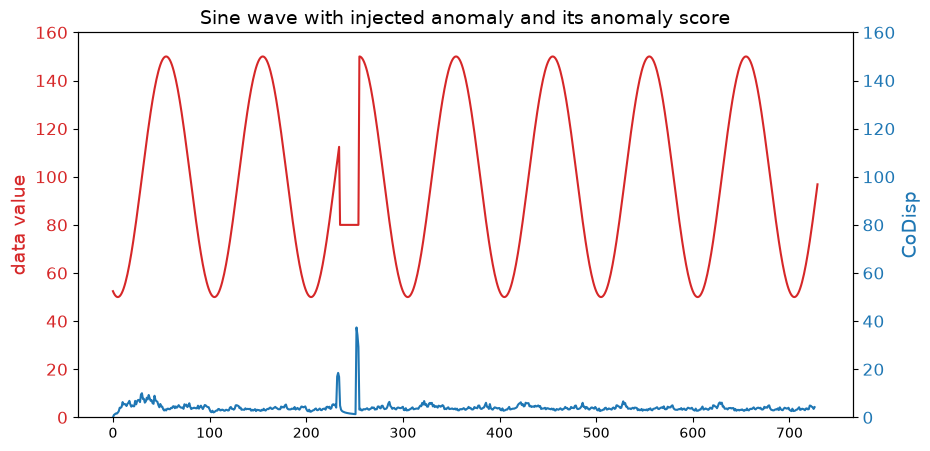

In [10]:
# Plot the original signal and its anomaly score on separate y-axes.
# Score peaks identify time windows that deserve closer inspection.
# Visualize the original time series together with its CoDisp score.
fig, ax1 = plt.subplots(figsize=(10, 5))

ax1.set_ylabel("data value", color="tab:red", size=14)
ax1.plot(sine_wave, color="tab:red")
ax1.tick_params(axis="y", labelcolor="tab:red", labelsize=12)
ax1.set_ylim(0, 160)

ax2 = ax1.twinx()
ax2.set_ylabel("CoDisp", color="tab:blue", size=14)
ax2.plot(pd.Series(average_codisp).sort_index(), color="tab:blue")
ax2.tick_params(axis="y", labelcolor="tab:blue", labelsize=12)
ax2.grid(False)
ax2.set_ylim(0, 160)

plt.title("Sine wave with injected anomaly and its anomaly score", size=14)
plt.show()

## RRCF on my there data sets 
As before im gonna reuse data sets from previous excercies:
* Bundesliga heights
* IPL first-innings totals
* MonzaGP 2024 Lap times 

In [11]:
import pandas as pd
import kagglehub
from scipy import stats

# Download (cached from Exercise 1)
fifa_path = kagglehub.dataset_download("stefanoleone992/fifa-22-complete-player-dataset")
ipl_path = kagglehub.dataset_download("patrickb1912/ipl-complete-dataset-20082020")
f1_path = kagglehub.dataset_download("rohanrao/formula-1-world-championship-1950-2020")

# 1) Bundesliga heights
players = pd.read_csv(os.path.join(fifa_path, "players_22.csv"), low_memory=False)
heights = players.loc[players["league_name"] == "German 1. Bundesliga", "height_cm"].dropna().astype(float).to_numpy()

# 2) IPL first-innings totals (full 20-over matches, no rain rule)
matches = pd.read_csv(os.path.join(ipl_path, "matches.csv"))
full_matches = matches[(matches["target_overs"] == 20) & (matches["method"].isna())]
ipl_totals = (full_matches["target_runs"].dropna() - 1).astype(float).to_numpy()

# 3) F1 lap times, 2024 Italian Grand Prix (raceId 1136)
RACE_ID = 1136
lap_times = pd.read_csv(os.path.join(f1_path, "lap_times.csv"))
drivers = pd.read_csv(os.path.join(f1_path, "drivers.csv"))
pit_stops = pd.read_csv(os.path.join(f1_path, "pit_stops.csv"))

laps = lap_times[lap_times["raceId"] == RACE_ID].merge(drivers[["driverId", "code"]], on="driverId")
laps["lap_s"] = laps["milliseconds"] / 1000

# Pit-stop time is counted in the lap after the stop, so shift by one
race_pits = pit_stops[pit_stops["raceId"] == RACE_ID][["driverId", "lap"]]
race_pits["lap"] = race_pits["lap"] + 1
race_pits["pit_lap"] = True
laps = laps.merge(race_pits, on=["driverId", "lap"], how="left")
laps["pit_lap"] = laps["pit_lap"].eq(True)

lap_seconds = laps["lap_s"].to_numpy()

datasets = {
    "Bundesliga height (cm)": heights,
    "IPL first-innings total (runs)": ipl_totals,
    "F1 Monza 2024 lap time (s)": lap_seconds,
}

for name, values in datasets.items():
    print(f"{name}: {values.size} values")

Bundesliga height (cm): 551 values
IPL first-innings total (runs): 1062 values
F1 Monza 2024 lap time (s): 1008 values


In [12]:
num_trees = 100
tree_size = 256
rng = np.random.default_rng(0)

rrcf_scores = {}
rrcf_anom = {}

for name, values in datasets.items():
    X = values.reshape(-1, 1)
    n_samples = X.shape[0]

    # Build num_trees trees, each from a random subset of tree_size points (as in Part III)
    forest = []
    for _ in range(num_trees):
        indexes = rng.choice(n_samples, size=tree_size, replace=False)
        forest.append(rrcf.RCTree(X[indexes], index_labels=indexes))

    # Average the CoDisp of each point over all trees that contain it
    avg_codisp = pd.Series(0.0, index=np.arange(n_samples))
    appearance_count = np.zeros(n_samples, dtype=int)
    for tree in forest:
        codisp = pd.Series({leaf: tree.codisp(leaf) for leaf in tree.leaves})
        avg_codisp.loc[codisp.index] += codisp
        np.add.at(appearance_count, codisp.index.to_numpy(dtype=int), 1)
    avg_codisp /= np.maximum(appearance_count, 1)

    # Flag the top 1% of scores, as in the professor's example
    threshold = avg_codisp.quantile(0.99)
    rrcf_scores[name] = avg_codisp.to_numpy()
    rrcf_anom[name] = (avg_codisp > threshold).to_numpy()

    print(f"{name}: threshold CoDisp = {threshold:.2f}, anomalies = {rrcf_anom[name].sum()}")

Bundesliga height (cm): threshold CoDisp = 24.67, anomalies = 6
IPL first-innings total (runs): threshold CoDisp = 38.45, anomalies = 11
F1 Monza 2024 lap time (s): threshold CoDisp = 37.94, anomalies = 11


pit-stop lap  False  True 
RRCF anomaly              
False           973     24
True              5      6
    code  lap    lap_s  pit_lap
158  NOR   53   81.432    False
307  VER   43   81.745    False
904  BOT    1   96.375    False
956  ZHO    1   96.732    False
694  TSU    7  100.319    False
597  MAG   15  107.023     True
849  STR   51  110.980     True
541  RIC   12  112.188     True
329  RUS   12  113.412     True
779  HUL   33  116.554     True
752  HUL    6  120.178     True


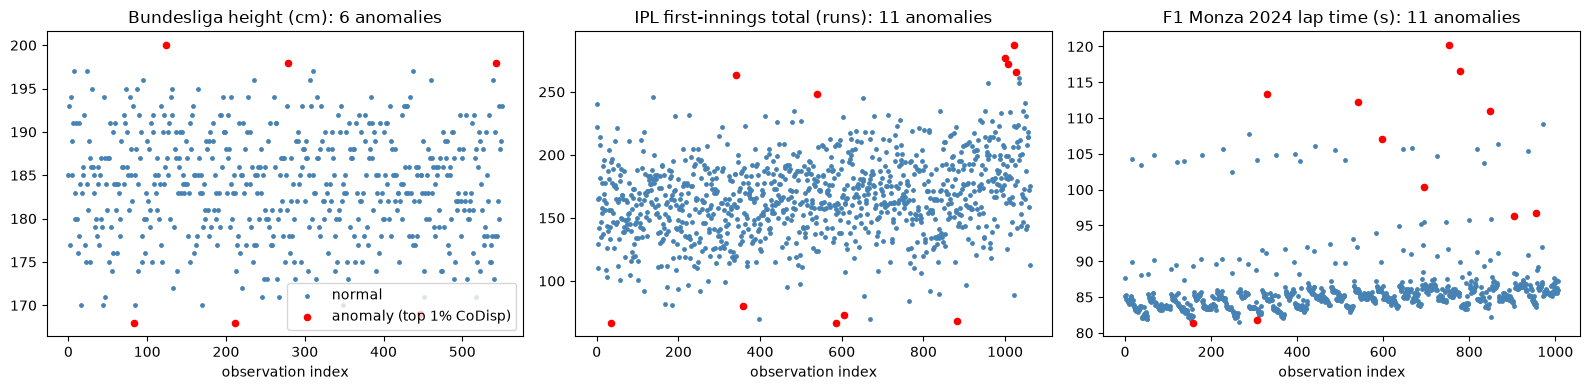

In [13]:
# F1: are the 11 anomalies pit stops?
laps["rrcf_anom"] = rrcf_anom["F1 Monza 2024 lap time (s)"]
print(pd.crosstab(laps["rrcf_anom"], laps["pit_lap"], rownames=["RRCF anomaly"], colnames=["pit-stop lap"]))
print(laps[laps["rrcf_anom"]][["code", "lap", "lap_s", "pit_lap"]].sort_values("lap_s"))

# Every data point with its RRCF result
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (name, values) in zip(axes, datasets.items()):
    anom = rrcf_anom[name]
    idx = np.arange(values.size)
    ax.scatter(idx[~anom], values[~anom], s=6, color="steelblue", label="normal")
    ax.scatter(idx[anom], values[anom], s=20, color="red", label="anomaly (top 1% CoDisp)")
    ax.set_title(f"{name}: {anom.sum()} anomalies")
    ax.set_xlabel("observation index")
axes[0].legend()
plt.tight_layout()
plt.show()

## Task 5: Interpretation

The threshold is the top 1% of CoDisp scores, as in the example above. So the number of anomalies is fixed at about 1% of each data set. The interesting part is which points are flagged.

**F1:** RRCF flagged 7 of the 30 pit stops. These are the slowest and most isolated ones (104 to 120 s). The other 23 pit-stop laps lie close together around 104 to 106 s. Removing one of them barely changes the tree, because similar points remain. Their CoDisp stays low (masking). RRCF also flagged slow first laps and one of the fastest laps of the race (Hamilton, last lap).

**Heights and IPL:** The anomalies are the most extreme values at both ends: the shortest and tallest players, and the lowest and highest totals.

**Comparison of all methods (F1 pit stops found out of 30):**

| Method | Anomalies | Pit stops found |
|---|---|---|
| 3σ (Ex1) | 31 | 30 |
| Box plot (Ex2) | 74 | 30 |
| DBSCAN noise (Ex3) | 7 | 6 |
| Isolation Forest, s > 0.6 (Ex4) | 75 | 30 |
| RRCF, top 1% (Ex5) | 11 | 7 |

**Conclusion:** RRCF behaves like DBSCAN. It finds isolated points, not groups of similar anomalies. A threshold has to be chosen, because CoDisp has no fixed scale. RRCF is designed for streaming data, where points are added and removed over time (part IV). For a fixed one-dimensional data set like mine, the simpler methods (3σ, box plot) found the pit stops just as well.